# Project 25: Messy Excel Report Parser

Analisis Q1-Q15. Semua tabel dibaca dari `results/` (hasil skrip Python dan SQL). Data adalah simulasi: 36 laporan Excel buatan dengan kunci jawaban.

In [1]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd()
while not (ROOT / 'results').exists():
    ROOT = ROOT.parent
R = lambda f: pd.read_csv(next((ROOT / 'results' / d / f) for d in ('1-data-preparation', '2-analysis', '3-presentation') if (ROOT / 'results' / d / f).exists()))
pd.options.display.float_format = '{:.6g}'.format
pd.options.display.max_colwidth = 70
plt.rcParams.update({'figure.figsize': (9, 3.4), 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, GREY, ORANGE = '#1A73E8', '#9AA0A6', '#E8710A'

## Q1. Masalah layout dan jumlah file yang terkena

In [2]:
R('layout_taxonomy.csv')

,problem,description,files,layout1,layout2,layout3,layout4,layout5,layout6
0,merged_header,Header digabung (merged cell) di dalam tabel,12,0,0,6,0,0,6
1,multi_table,Lebih dari satu tabel dalam satu sheet,12,6,0,0,6,0,0
2,subtotal_inside,Baris subtotal atau total di tengah data,12,6,6,0,0,0,0
3,dates_as_columns,Tanggal berjajar sebagai kolom,6,6,0,0,0,0,0
4,hidden_or_footnote,Baris tersembunyi atau catatan kaki,6,0,0,0,0,0,6
5,inconsistent_labels,"Nama stasiun, ukuran, atau tanggal ditulis tidak seragam",6,0,0,0,0,6,0
6,sheet_per_period,Satu sheet per minggu,6,0,0,6,0,0,0
7,text_numbers,Angka tersimpan sebagai teks dengan satuan,6,0,0,0,0,6,0
8,extra_columns,Kolom catatan atau paraf di luar data,3,3,0,0,0,0,0


## Q2. Template mana yang paling sulit

In [3]:
R('template_difficulty.csv')

,layout,reader,config_files,config_lines,config_keys,cells,anomaly_rows,anomaly_per_1000_cells,unresolved_cells,unresolved_per_1000_cells
0,1,date_columns,2,17,22,10800,217,20.0926,66,6.11111
1,2,date_shift_groups,1,19,22,10800,218,20.1852,6,0.555556
2,3,wide_groups,2,17,21,10800,216,20,162,15
3,4,flat,1,17,23,10800,216,20,162,15
4,5,flat,1,17,24,5400,0,0,0,0
5,6,wide_groups,1,19,22,5400,108,20,84,15.5556


## Q3. Rekonsiliasi: subtotal laporan vs jumlah hasil parsing

In [4]:
display(R('reconciliation_summary.csv')); R('reconciliation_typos.csv')

,layout,kind,subtotals,match_raw,match_final,recovered_this,recovered_other,open_bad_cells,suspect_subtotal,match_rate_raw,match_rate_final
0,1,subtotal,300,173,269,96,0,31,0,0.576667,0.896667
1,2,row_total,1800,1712,1800,85,3,0,0,0.951111,1
2,2,subtotal,2100,1868,2095,71,156,3,2,0.889524,0.997619


,source_file,sheet,report_cell,report_total,parsed_total_final,diff_final,block
0,laporan_G2_2026-04.xlsx,Laporan,H503,287,197,-90,2026-05-07|Shift 2|slot 3
1,laporan_G2_2026-07.xlsx,Laporan,F367,284,194,-90,2026-08-12|Shift 1|slot 2


## Q4. Kecocokan dengan data rapi asli

In [5]:
display(R('accuracy_summary.csv')); R('accuracy_by_layout.csv')

,item,value
0,sel nilai pada kunci jawaban,54000
1,sel yang ada di hasil parsing,54000
2,sel sama persis dengan kunci jawaban,53520
3,persen sama persis,0.991111
4,sel berstatus ok atau fixed,53520
5,sel ok atau fixed yang sama persis,53520
6,persen ok atau fixed yang sama persis,1
7,sel berstatus fixed,492
8,sel fixed yang sama persis,492
9,"sel berstatus flagged (nilai dipertahankan, mencurigakan)",161


,layout,cells,exact,ok,fixed,flagged,missing,exact_rate,unflagged_exact_rate
0,1,10800,10734,10584,150,27,39,0.993889,1
1,2,10800,10794,10584,210,2,4,0.999444,1
2,3,10800,10638,10584,54,54,108,0.985,1
3,4,10800,10638,10584,54,54,108,0.985,1
4,5,5400,5400,5400,0,0,0,1,1
5,6,5400,5316,5292,24,24,60,0.984444,1


## Q5. Pareto anomali per jenis dan layout

,issue_type,n,fixed,flagged,dropped,share,cum_share
0,dash,246,88,158,0,0.252308,0.252308
1,text_na,246,85,161,0,0.252308,0.504615
2,outlier,240,79,161,0,0.246154,0.750769
3,unit_text,240,240,0,0,0.246154,0.996923
4,subtotal_mismatch,2,0,2,0,0.00205128,0.998974
5,duplicate_sheet,1,0,0,1,0.00102564,1


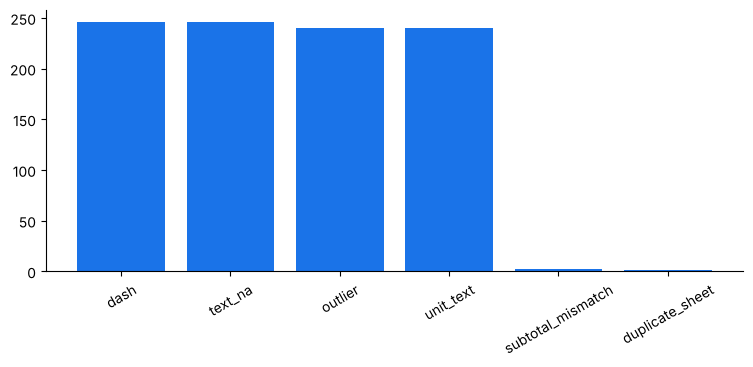

,issue_type,layout1,layout2,layout3,layout4,layout6
0,dash,54,54,54,54,30
1,text_na,54,54,54,54,30
2,outlier,54,54,54,54,24
3,unit_text,54,54,54,54,24
4,subtotal_mismatch,0,2,0,0,0
5,duplicate_sheet,1,0,0,0,0


In [6]:
t = R('anomaly_by_type.csv'); display(t)
fig, ax = plt.subplots(); ax.bar(t.issue_type, t.n, color=BLUE); plt.xticks(rotation=30); plt.show()
R('anomaly_by_layout.csv')

## Q6-Q7. Perubahan layout: apa yang terjadi dan berapa baris config yang diubah

In [7]:
display(R('robustness_scenarios.csv')[['id','scenario','old_config','new_config','config_lines_changed','lookup_lines_changed','python_lines_changed']]); R('config_changes.csv')

,id,scenario,old_config,new_config,config_lines_changed,lookup_lines_changed,python_lines_changed
0,R1,Layout 1 bulan ke-4: judul 4 baris dan kolom Catatan/Paraf,berhenti: UnknownTemplate,1786 dari 1786 sel tepercaya cocok,2,0,0
1,R2,Layout 3 bulan ke-4: nama sheet 'Minggu 1' menjadi 'Wk1',berhenti: UnknownTemplate,1773 dari 1773 sel tepercaya cocok,2,0,0
2,S1,Layout 4: satu kolom kosong disisipkan di depan,berhenti: UnknownTemplate,1773 dari 1773 sel tepercaya cocok,4,0,0
3,S2,Layout 2: dua baris judul ditambahkan di atas,berhenti: UnknownTemplate,1798 dari 1798 sel tepercaya cocok,1,0,0
4,S3,Layout 5: kolom Operator disisipkan di tengah tabel,berhenti: UnknownTemplate,900 dari 900 sel tepercaya cocok,2,0,0
5,S4,Layout 1: sheet diganti nama dari 'Sheet1' menjadi 'Output',berhenti: UnknownTemplate,1792 dari 1792 sel tepercaya cocok,2,0,0
6,S5,Layout 6: sheet baru 'Catatan' ditambahkan di file,"diparse, 886 dari 886 sel tepercaya cocok",886 dari 886 sel tepercaya cocok,0,0,0
7,S6,Layout 3: nama stasiun baru yang belum dikenal ('Filler 2'),berhenti: UnknownLabel,1773 dari 1773 sel tepercaya cocok,0,1,0
8,S7,Workbook yang bukan laporan produksi,berhenti: UnknownTemplate,berhenti: UnknownTemplate,0,0,0


,layout,from_config,to_config,lines_in_new_file,lines_changed,lines_changed_excluding_id_description,python_lines_changed
0,1,L1_v1,L1_v2,17,4,2,0
1,3,L3_v1,L3_v2,17,4,2,0
2,0,(tidak ada),template baru dari nol (rata-rata 6 template v1),18,18,16,0


## Q8-Q10. Empat metode (waktu proses adalah waktu mesin; waktu pembuatan manusia tidak diukur)

In [8]:
display(R('method_benchmark.csv').drop(columns=['build_minutes','fix_minutes','note'])); display(R('method_matrix.csv')); R('method_situations.csv')

,method,scenario,n_files,build_size,build_unit,run_seconds,result_match,result_match_before_fix,fix_size,fix_unit,status
0,Rumus Excel,"S1 satu file (layout 1, Mar)",1,17,rumus unik + 6 parameter,0.942028,0.985,NaN,NaN,NaN,diukur
1,SQL (DuckDB),"S1 satu file (layout 1, Mar)",1,18,baris SQL,0.945232,0.985,NaN,NaN,NaN,diukur
2,Python (parser),"S1 satu file (layout 1, Mar)",1,17,baris config (+496 baris mesin dipakai ulang),0.0712228,0.995556,NaN,NaN,NaN,diukur
3,Power Query,"S1 satu file (layout 1, Mar)",1,25,baris M,NaN,NaN,NaN,NaN,NaN,tidak dijalankan
4,Rumus Excel,S2 enam file layout 1 (Mar-Agu),6,17,rumus unik + 6 parameter,6.00881,0.985,NaN,NaN,NaN,diukur
5,SQL (DuckDB),S2 enam file layout 1 (Mar-Agu),6,18,baris SQL,5.55853,0.985,NaN,NaN,NaN,diukur
6,Python (parser),S2 enam file layout 1 (Mar-Agu),6,34,baris config (2 file config),0.30849,0.993889,NaN,NaN,NaN,diukur
7,Power Query,S2 enam file layout 1 (Mar-Agu),6,32,baris M,NaN,NaN,NaN,NaN,NaN,tidak dijalankan
8,Python (parser),"S3 36 file, 6 layout",36,140,baris config (8 file config),2.95547,0.991111,NaN,NaN,NaN,diukur
9,Rumus Excel,"S3 36 file, 6 layout",36,NaN,NaN,NaN,NaN,NaN,NaN,NaN,tidak dikerjakan


,criterion,basis,excel_formula,sql,python_parser,power_query
0,Waktu proses satu file (detik),diukur,0.9420278420002433,0.9452320609998424,0.07122279399936815,NaN
1,"Kecocokan dengan kunci jawaban, satu file (persen)",diukur,0.985,0.985,0.9955555555555555,NaN
2,Perubahan untuk layout bulan ke-4,diukur,1 sel parameter,tidak perlu (query tetap benar),2 baris config (file baru),1 nilai parameter (tidak diuji)
3,Hasil bila layout berubah dan tidak ada yang diubah (persen sel be...,diukur,90.6%,98.5%,0.0%,tidak diuji
4,Perilaku bila layout berubah tanpa perubahan,diukur,"hasil tetap keluar, 2 tanggal terakhir hilang tanpa peringatan",hasil tetap benar pada kasus ini,berhenti dengan pesan template tidak dikenal; tidak ada angka ditulis,tidak diuji
5,Rekonsiliasi dengan subtotal laporan,diukur,tidak ada,tidak ada,ada (4.200 subtotal),tidak ada
6,Pemulihan sel kotor lewat subtotal,diukur,tidak ada,tidak ada,ada (252 sel),tidak ada
7,Jejak sel asal sampai alamat sel,penilaian,ada (baris dan kolom sumber),ada (nomor baris dan kolom),ada (sheet dan sel),ada (kolom Row)
8,Banyak file sekaligus,penilaian,satu workbook per file,perlu loop di luar SQL,ya (pilih template otomatis),"ya (folder), template dipilih manual"
9,Keahlian yang dibutuhkan,penilaian,"Excel (INDEX, MATCH)",SQL dan sedikit Python untuk memuat sel,Python dan YAML,Excel dan bahasa M (menu)


,situation,recommended_method,reason,basis
0,"End user di lini produksi, satu atau dua file, tanpa programmer",Rumus Excel,Tanpa instalasi; perubahan layout cukup mengubah satu sel paramete...,diukur
1,Tim non-programmer yang rutin mengolah banyak file satu layout,Power Query,Refresh dari folder tanpa menulis kode; perubahan layout lewat par...,penilaian (belum dijalankan)
2,Banyak file dengan banyak layout dan perlu bukti kebenaran,Python (parser),"Pilih template otomatis, rekonsiliasi dengan subtotal, pemulihan d...",diukur
3,Data sudah berupa tabel di database,SQL (DuckDB),"Sekali tabel sel termuat, query bisa diulang dan diaudit; tidak me...",diukur


## Q11. Pivot dari tabel tidy vs kunci jawaban dan total laporan

In [9]:
p = R('pivot_vs_truth.csv'); display(p[['station','block_month','produced_diff_pct','reject_rate_diff_pp','missing_cells','flagged_cells']].head(12)); R('pivot_vs_report_totals.csv')

,station,block_month,produced_diff_pct,reject_rate_diff_pp,missing_cells,flagged_cells
0,Blow Molding,2026-03,0,0,0,0
1,Blow Molding,2026-04,0,0,0,0
2,Blow Molding,2026-05,0,-0.00266801,1,0
3,Blow Molding,2026-06,0,0,0,0
4,Blow Molding,2026-07,0,0.0393435,0,1
5,Blow Molding,2026-08,0,0,0,0
6,Capping,2026-03,0.0335745,-0.00473923,12,5
7,Capping,2026-04,0.0263328,0.00073995,5,3
8,Capping,2026-05,0.0171385,0.00954782,8,4
9,Capping,2026-06,-0.017751,0.0521835,13,2


,source_file,report_total,pivot_total_raw,pivot_total_final,n_subtotals,layout,diff_raw,diff_final,same_after_repair
0,laporan_G1_2026-03.xlsx,2.2537e+06,2.28018e+06,2.25992e+06,25,1,26478,6224,False
1,laporan_G1_2026-04.xlsx,2.25506e+06,2.36753e+06,2.29267e+06,25,1,112465,37605,False
2,laporan_G1_2026-05.xlsx,2.25437e+06,2.33251e+06,2.26087e+06,25,1,78144,6499,False
3,laporan_G1_2026-06.xlsx,2.2562e+06,2.32454e+06,2.31168e+06,25,1,68333,55470,False
4,laporan_G1_2026-07.xlsx,2.25266e+06,2.248e+06,2.2601e+06,25,1,-4656,7448,False
5,laporan_G1_2026-08.xlsx,2.24046e+06,2.34363e+06,2.30442e+06,25,1,103169,63959,False
6,laporan_G2_2026-03.xlsx,2.25471e+06,2.3232e+06,2.25471e+06,50,2,68498,0,True
7,laporan_G2_2026-04.xlsx,2.25052e+06,2.31752e+06,2.25052e+06,50,2,67004,0,True
8,laporan_G2_2026-05.xlsx,2.2532e+06,2.30995e+06,2.2532e+06,50,2,56749,0,True
9,laporan_G2_2026-06.xlsx,2.24378e+06,2.35939e+06,2.24378e+06,50,2,115610,0,True


## Q12. Pola setelah enam laporan bulanan digabung

In [10]:
display(R('station_reject_rate.csv')); display(R('trend_slopes.csv')); R('rate_by_size_shift.csv')

,station,produced,reject,reject_rate
0,Blow Molding,6.74514e+06,134918,0.0200022
1,Filling,6.66944e+06,99859,0.0149726
2,Labeling,6.65563e+06,80826,0.012144
3,Capping,6.63486e+06,66622,0.0100412
4,Rinsing,6.75969e+06,54200,0.00801812
5,Cartoning,6.73695e+06,47513,0.00705259
6,Mixing,6.70872e+06,40100,0.00597729
7,Shrink Wrap,6.64168e+06,33194,0.00499783
8,Water Treatment,6.74008e+06,26917,0.00399357
9,Palletizing,6.61408e+06,20135,0.00304426


,station,slope_pp_per_block,rate_first_block,rate_last_block,rate_min_block,rate_max_block
0,Blow Molding,0.00481445,0.0199812,0.0200858,0.0198083,0.0202543
1,Capping,-0.00061839,0.00999395,0.00990474,0.00990474,0.0102127
2,Cartoning,0.00283802,0.00692866,0.0071638,0.00692866,0.0071638
3,Filling,-0.00222023,0.0151275,0.0149772,0.0149089,0.0151275
4,Labeling,0.00389286,0.0119773,0.0122183,0.0119773,0.0122183
5,Mixing,0.000421193,0.00598971,0.00601803,0.00585373,0.00607033
6,Palletizing,0.0017999,0.00298087,0.00312473,0.00295669,0.00312473
7,Rinsing,-0.00223857,0.0080341,0.00793025,0.00793025,0.00810974
8,Shrink Wrap,-0.0013647,0.00500286,0.00495833,0.00495833,0.00508292
9,Water Treatment,0.00117221,0.00396632,0.00408611,0.00392107,0.00408611


,dimension,group,produced,reject,reject_rate
0,ukuran,"1,5 L",13490659,121156,0.00898073
1,ukuran,330 ml,28805913,260349,0.00903804
2,ukuran,600 ml,25202338,227584,0.00903027
3,shift,Shift 1,33747741,304560,0.0090246
4,shift,Shift 2,33751169,304529,0.00902277


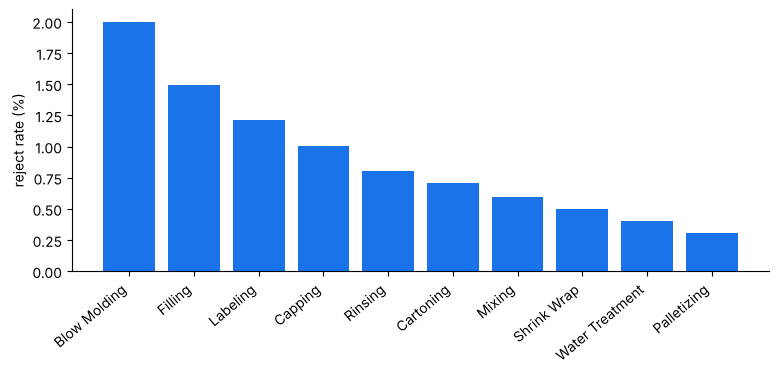

In [11]:
r = R('station_reject_rate.csv'); plt.bar(r.station, r.reject_rate * 100, color=BLUE); plt.xticks(rotation=40, ha='right'); plt.ylabel('reject rate (%)'); plt.show()

## Q13-Q14. Dampak waktu (asumsi, estimated) dan sel salah yang tertangkap

In [12]:
display(R('impact_time.csv')); display(R('impact_scenarios.csv').pivot(index='reports_per_month', columns='minutes_per_report', values='hours_saved_per_year')); R('errors_caught.csv')

,item,value,unit,basis
0,Laporan per bulan,6,laporan,asumsi
1,Menit copy-paste dan pengecekan per laporan,30,menit,asumsi
2,Jam copy-paste per tahun,36,jam,"estimated, simulated"
3,Waktu parser untuk 36 file,2.94307,detik,diukur
4,Waktu parser untuk laporan satu bulan (6 file),0.490512,detik,diukur
5,Jam parser per tahun,0.00163504,jam,diukur
6,Jam dihemat per tahun,35.9984,jam,"estimated, simulated"


minutes_per_report,15,30,60
reports_per_month,,,
3,9,18,36
6,18,36,72
12,36,72,144
24,72,144,288


,item,value
0,Sel angka salah atau hilang di laporan (tanpa unit_text dan duplikat),734
1,di file yang punya subtotal (layout 1 dan 2),326
2,"di file tanpa subtotal (layout 3, 4, 6)",408
3,Sel salah yang tercatat di log anomali,734
4,Sel salah yang lolos tanpa tercatat,0
5,Sel berformat teks (unit_text) yang dibersihkan,240
6,Sel salah yang nilainya dipulihkan tepat lewat subtotal,252
7,Pembanding rekap copy-paste manual (tidak diukur),NaN


## Q15. Kejadian yang ditanam: terdeteksi?

In [13]:
display(R('validation_planted.csv')); R('validation_checks.csv')

,fact_id,fact,check,planted,detected,note,recall
0,1,Enam layout dikenali,file yang cocok dengan layout aslinya,36,36,"template dipilih otomatis dari isi sel, bukan dari nama file",1
1,2,Perubahan layout bulan ke-4,file layout 1 dan 3 memakai config yang benar,12,12,bulan 1-3: config v1; bulan 4-6: config v2,1
2,3,Subtotal salah ketik,subtotal salah yang tercatat sebagai subtotal_mismatch,2,2,keduanya di layout 2,1
3,4,Sheet ganda,sheet ganda yang dibuang,1,1,dikenali dari nama salinan dan kemiripan isi,1
4,5,Sel kotor: teks 'n/a',sel yang benar-benar berubah di file dan tercatat,246,246,NaN,1
5,5,Sel kotor: tanda '-',sel yang benar-benar berubah di file dan tercatat,246,246,NaN,1
6,5,Sel kotor: angka kali 10,sel yang benar-benar berubah di file dan tercatat,240,240,NaN,1
7,5,Sel kotor: angka dengan satuan,sel yang benar-benar berubah di file dan tercatat,240,240,NaN,1
8,5,Sel kotor: sel kosong,sel yang benar-benar berubah di file dan tercatat,0,0,tidak ada yang berubah: pembuat data tidak benar-benar mengosongka...,NaN


,question,check,n_tested,n_pass,result
0,Q4,Jumlah sel hasil parsing = jumlah sel kunci jawaban,54000,54000,lulus
1,Q4,"Tidak ada kunci ganda (tanggal, shift, slot, stasiun, ukuran, metrik)",54000,54000,lulus
2,Q4,Setiap sel kunci jawaban ada di hasil parsing,54000,54000,lulus
3,Q15,Anomali tercatat yang bukan sel yang ditanam (positif palsu),975,975,lulus
4,Q6,Setiap file cocok dengan tepat satu template,36,36,lulus
5,Q6,Parsing dua kali menghasilkan tabel tidy identik (SHA-256),1,1,lulus
6,Q4,Sel berstatus ok atau fixed yang berbeda dari kunci jawaban,53520,53520,lulus


## Cek silang SQL vs pandas

In [14]:
x = R('crosscheck_sql.csv'); print(f"{int(x.match.sum())} dari {len(x)} pemeriksaan cocok"); x

18 dari 18 pemeriksaan cocok


,check,sql,pandas,diff,match
0,sel berstatus ok,53028,53028,0,True
1,sel berstatus fixed,492,492,0,True
2,sel berstatus flagged,161,161,0,True
3,sel berstatus missing,319,319,0,True
4,sel pada kunci jawaban,54000,54000,0,True
5,sel sama persis dengan kunci jawaban,53520,53520,0,True
6,subtotal cocok sebelum pemulihan,3753,3753,0,True
7,subtotal selisih sebelum pemulihan,447,447,0,True
8,subtotal cocok sesudah pemulihan,4164,4164,0,True
9,anomali unit_text,240,240,0,True
